# Análise exploratória — versão interativa

Este notebook reproduz o relatório `results/eda/RELATORIO_EDA.md` **com o mesmo código**
(`scripts/eda.py`) e acrescenta, em cada seção:

- **A pergunta**: o que a análise quer responder e por que isso importa para o modelo;
- **O relatório**: tabelas e figuras geradas pelas funções do `eda.py`;
- **Como ler**: o que observar nas figuras;
- **Explore**: células com parâmetros (em `MAIÚSCULAS`) para alterar e rodar de novo.

Para abrir: `.venv\Scripts\jupyter lab notebooks/eda.ipynb` (a partir da pasta POC-I) e
*Run → Run All Cells*. A base em `data/` precisa existir (`scripts/build_dataset.py`).
O DIMACS não é usado aqui.

**Vocabulário rápido**

| termo | significado |
|---|---|
| camada A / S / B | grafos sintéticos principais (n ≤ 1.000) / de escala (n até 10.000) / com rótulo por passo (rollout) |
| ER, BA | Erdős–Rényi (arestas independentes, prob. p) e Barabási–Albert (ligação preferencial, m arestas por vértice novo) |
| candidato | vértice sugerido por uma das 4 heurísticas num passo da construção |
| rótulo 3b | 1 se o candidato, completado com DSATUR e RLF, atinge o menor nº de cores do passo |
| passo informativo | passo em que ao menos um candidato tem rótulo 0 (há escolha errada possível) |
| oráculo | coloração que, a cada passo, segue o candidato de melhor valor |

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path[:0] = [str(ROOT), str(ROOT / "scripts")]

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import eda
from eda import FEATURE_DESC, FEATURES, H, HCOLOR, HNAME, WCATS, WCOLOR, model_label

DATA = ROOT / "data"
A = eda.load_tier(DATA, "A")                          # 1 linha por grafo (+ cores e tempos)
S = eda.load_tier(DATA, "S")
B = pd.read_parquet(DATA / "B" / "rollouts")          # 1 linha por (grafo, passo, candidato)
O = pd.read_parquet(DATA / "B" / "oracle")            # 1 linha por grafo da camada B
rep = eda.Report(None, inline=True)                   # exibe aqui, não grava arquivos
FAM = {"er": "#86b6ef", "ba": "#104281"}              # cores das famílias nos gráficos extras
print(f"A: {len(A)} grafos | S: {len(S)} | B: {B.graph_id.nunique()} grafos, {len(B):,} candidatos")

A: 2755 grafos | S: 63 | B: 813 grafos, 858,790 candidatos


## 1. Visão geral da base

**Pergunta.** Que tipos de grafo temos? Se a base só cobre algumas regiões do "espaço de
grafos", o modelo só pode aprender sobre essas regiões.

**Como ler.** Na Figura 1, cada coluna é um atributo global e cada linha, uma família. Repare
que as distribuições de ER e BA quase não se sobrepõem em `deg_cv` (heterogeneidade dos
graus) e em `clust_ratio` (agrupamento acima do esperado para a densidade).

## 1. Visão geral da base


Camada B: 813 grafos (subconjunto de A com n ≤ 500 e réplicas 0–2), 858.790 linhas de candidatos.


| camada | modelo | grafos | n_min | n_max | arestas_max | dens_min | dens_max |
|---|---|---|---|---|---|---|---|
| A | Barabási–Albert | 855 | 50 | 1000 | 210.000 | 0,004 | 0,429 |
| A | Erdős–Rényi | 1900 | 50 | 1000 | 474.750 | 0,038 | 0,954 |
| S | Barabási–Albert | 36 | 2000 | 10.000 | 199.600 | 0,000 | 0,020 |
| S | Erdős–Rényi | 27 | 2000 | 10.000 | 10.001.300 | 0,050 | 0,200 |



Medianas dos atributos globais na camada A:


| atributo | Barabási–Albert | Erdős–Rényi |
|---|---|---|
| nº de vértices (`n`) | 550 | 525 |
| nº de arestas (`m`) | 4.725 | 49.403 |
| densidade (`density`) | 0,0622 | 0,5 |
| grau mínimo (`deg_min`) | 8 | 171 |
| grau máximo (`deg_max`) | 120 | 232 |
| grau médio (`deg_mean`) | 18 | 200 |
| desvio do grau (`deg_std`) | 14,2 | 8,92 |
| coef. de variação do grau (`deg_cv`) | 0,742 | 0,0479 |
| grau máximo / grau médio (`deg_max_ratio`) | 4,9 | 1,14 |
| agrupamento médio (`avg_clustering`) | 0,149 | 0,5 |
| agrupamento / densidade (`clust_ratio`) | 2,29 | 1 |
| degenerescência (`degeneracy`) | 10 | 177 |
| degenerescência / grau máximo (`degen_ratio`) | 0,106 | 0,777 |


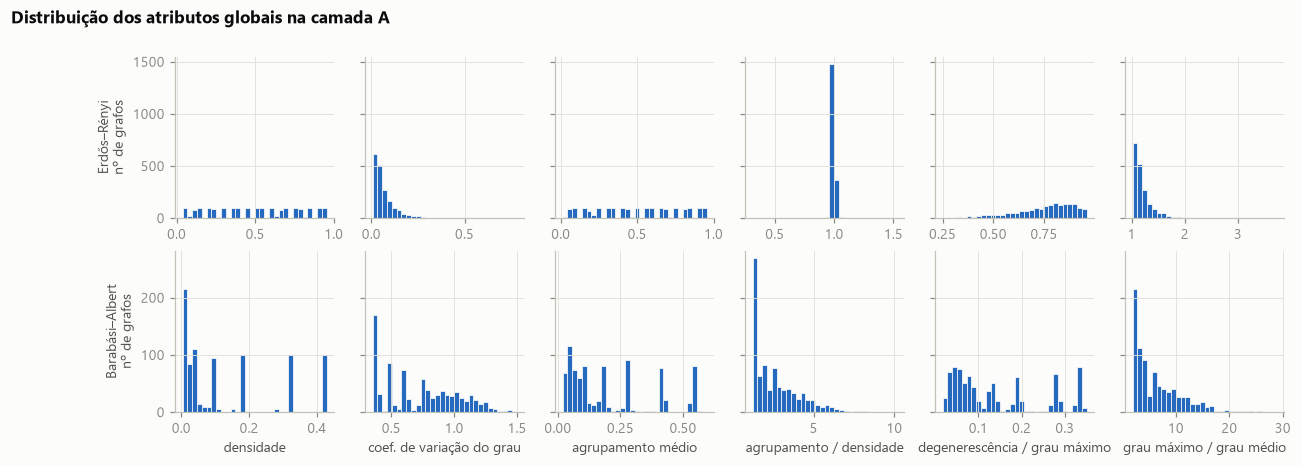

*Figura 1 — Distribuição dos atributos globais (camada A), por modelo gerador.*

Os grafos ER cobrem densidades de 0,05 a 0,95 com grau quase homogêneo (coeficiente de variação baixo) e agrupamento ≈ densidade (razão ≈ 1). Os BA são esparsos na maior parte da grade, com grau heterogêneo e agrupamento acima do esperado para a densidade. As duas famílias ocupam regiões quase disjuntas do espaço de atributos, o que limita o que se pode concluir sobre grafos "intermediários" (ex.: densos e heterogêneos).


In [2]:
eda.sec1_overview(rep, A, S, B[['graph_id']])

### Explore: onde ficam as duas famílias?
Cada ponto é um grafo da camada A. Troque os atributos dos eixos (qualquer nome da lista
`FEATURES`) para ver outras projeções.

atributos: n, m, density, deg_min, deg_max, deg_mean, deg_std, deg_cv, deg_max_ratio, avg_clustering, clust_ratio, degeneracy, degen_ratio


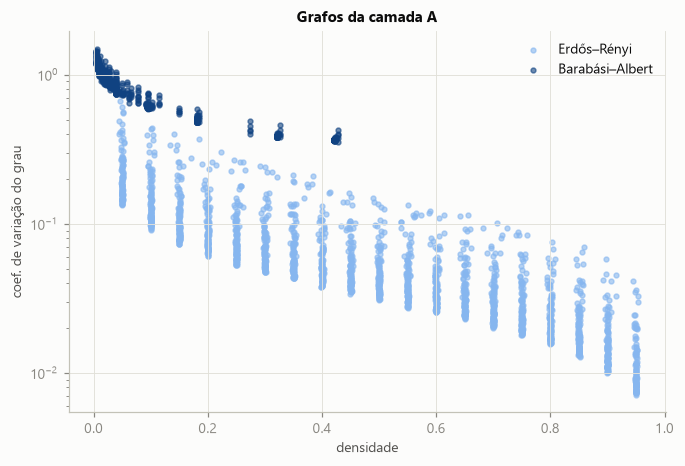

In [3]:
EIXO_X, EIXO_Y = "density", "deg_cv"      # ex.: "avg_clustering", "clust_ratio", "degen_ratio"
LOG_Y = True

print("atributos:", ", ".join(FEATURES))
fig, ax = plt.subplots(figsize=(7, 4.5))
for fam in ("er", "ba"):
    d = A[A.model == fam]
    ax.scatter(d[EIXO_X], d[EIXO_Y], s=10, alpha=0.6, color=FAM[fam], label=model_label(fam))
ax.set_xlabel(FEATURE_DESC[EIXO_X]); ax.set_ylabel(FEATURE_DESC[EIXO_Y])
if LOG_Y: ax.set_yscale("log")
ax.legend(); ax.set_title("Grafos da camada A")
plt.show()

## 2. Desempenho das heurísticas (camada A)

**Pergunta.** Alguma heurística domina? Se sim, onde? É isso que define o rótulo por grafo
("opção 1") e mostra quanto há a ganhar.

**Como ler.** Na Figura 2, à esquerda, a cor de cada célula é a heurística vencedora; à
direita, a intensidade é quanto o DSATUR usa a mais (vermelho) ou a menos (azul) que o RLF,
em % do melhor resultado. No ER quase tudo é vermelho (RLF melhor); no BA, azul (DSATUR
melhor). Welsh-Powell e a ordem aleatória nunca vencem sozinhas.

## 2. Desempenho das heurísticas (camada A, rótulo por grafo)


| heurística | melhor c/ empate (geral) | melhor sozinha (geral) | melhor c/ empate (ER) | melhor sozinha (ER) | melhor c/ empate (BA) | melhor sozinha (BA) | cores acima da melhor (média) | % acima da melhor (média) | % acima da melhor (máx.) |
|---|---|---|---|---|---|---|---|---|---|
| Aleatória | 0% | 0% | 0% | 0% | 0% | 0% | 12,48 | 36,9% | 166,7% |
| Welsh-Powell | 3% | 0% | 1% | 0% | 8% | 0% | 7,78 | 16,4% | 66,7% |
| DSATUR | 38% | 23% | 11% | 1% | 100% | 73% | 3,95 | 5,0% | 25,0% |
| RLF | 77% | 62% | 99% | 89% | 27% | 0% | 0,34 | 3,1% | 33,3% |



Categoria vencedora por grafo. "WP/aleatória" = Welsh-Powell ou ordem aleatória estritamente melhor que DSATUR e RLF — **não ocorre em nenhum grafo**: a disputa é sempre entre DSATUR e RLF.


| vencedora (categoria) | Barabási–Albert | Erdős–Rényi | geral |
|---|---|---|---|
| DSATUR | 73% | 1% | 23% |
| RLF | 0% | 89% | 62% |
| empate DSATUR = RLF | 27% | 9% | 15% |


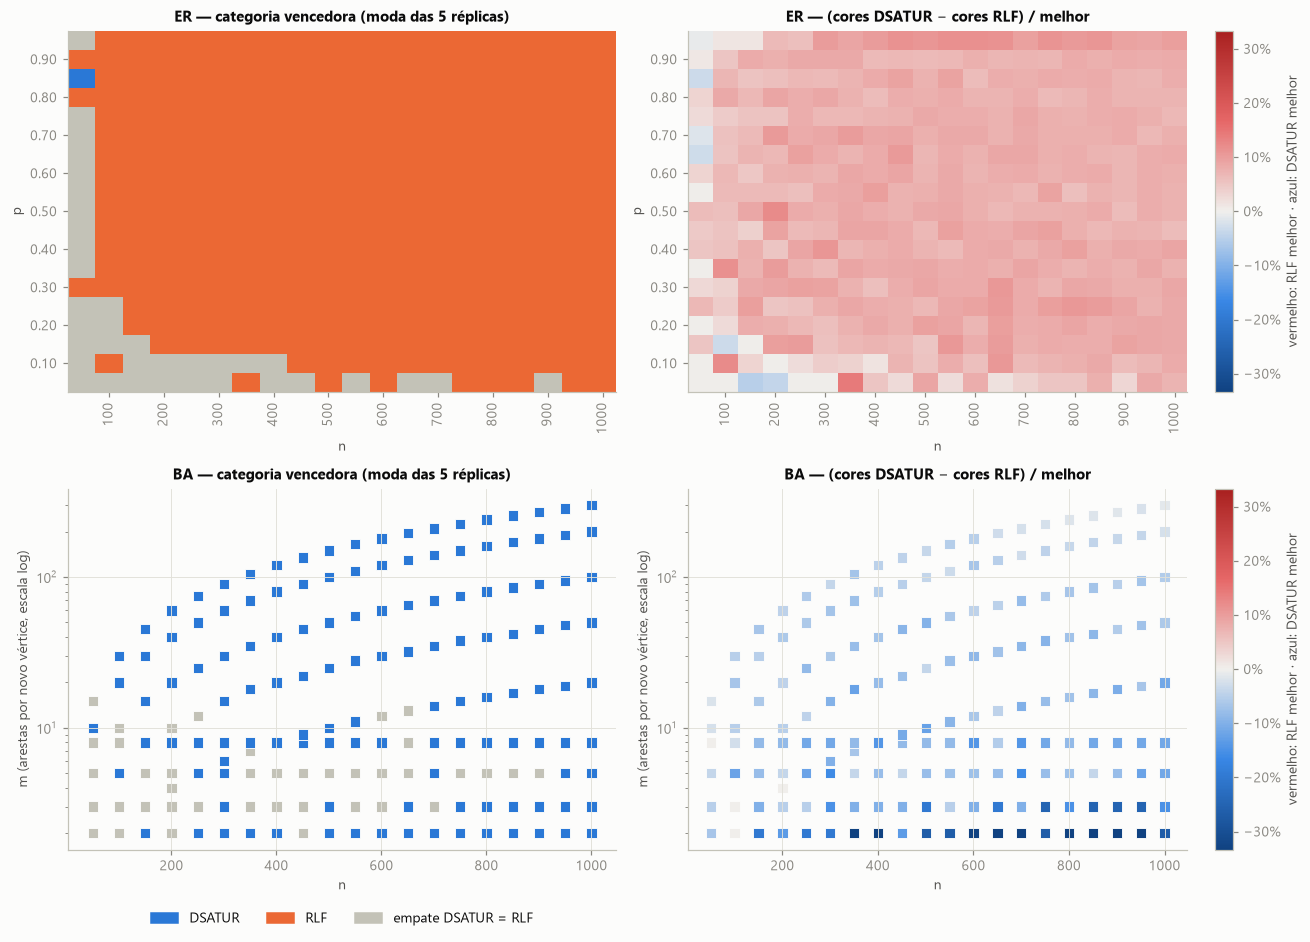

*Figura 2 — Heurística vencedora e diferença relativa DSATUR − RLF no espaço de parâmetros da camada A.*

No ER, o RLF é estritamente melhor que o DSATUR na maioria das réplicas para p em 0,10–0,95; os empates concentram-se em n pequeno ou p pequeno, onde as colorações usam poucas cores. No BA com m ≤ 8, DSATUR e RLF empatam em 41% dos grafos; com m > 8, o RLF vence sozinho em 0% e o DSATUR em 87%.


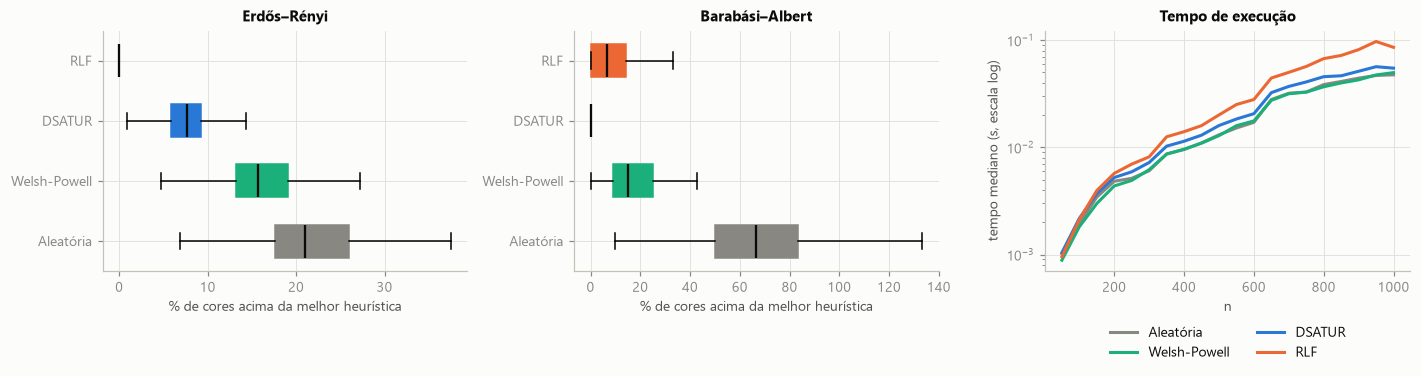

*Figura 3 — Excesso de cores em relação à melhor heurística (caixas sem pontos extremos) e tempo mediano por n.*

In [4]:
eda.sec2_heuristics(rep, A)

### Explore: nº de cores em função de n
Escolha a família e o parâmetro (p no ER, m no BA). As linhas são a média das 5 réplicas;
a tabela mostra as réplicas de um n específico.

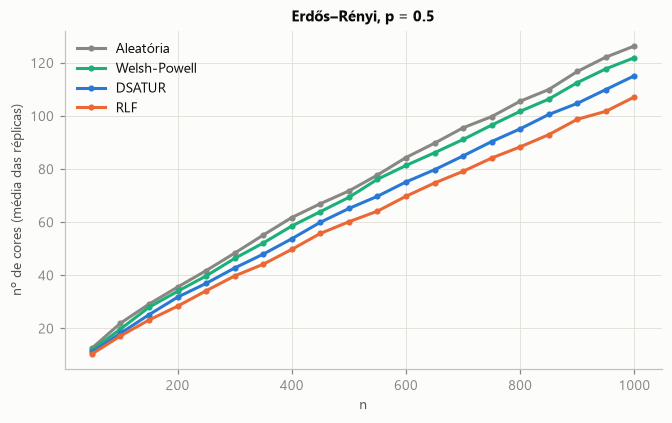

,graph_id,colors_random,colors_welsh_powell,colors_dsatur,colors_rlf,winner
1448,er_n500_p0.50_s0,72.0,71.0,66.0,60.0,RLF
1451,er_n500_p0.50_s2,72.0,69.0,66.0,59.0,RLF
1452,er_n500_p0.50_s4,73.0,69.0,65.0,61.0,RLF
1453,er_n500_p0.50_s1,69.0,68.0,64.0,61.0,RLF
1454,er_n500_p0.50_s3,73.0,70.0,65.0,60.0,RLF


In [5]:
FAMILIA, PARAM, N_TABELA = "er", 0.5, 500     # ex.: ("ba", 5, 500) ou ("er", 0.1, 1000)

d = A[(A.model == FAMILIA) & np.isclose(A.param, PARAM)]
if d.empty:
    print("combinação inexistente; valores de param:", sorted(A[A.model == FAMILIA].param.unique()))
else:
    fig, ax = plt.subplots(figsize=(7, 4))
    for h in H:
        s = d.groupby("n")[f"colors_{h}"].mean()
        ax.plot(s.index, s, color=HCOLOR[h], label=HNAME[h], marker="o", markersize=3)
    ax.set_xlabel("n"); ax.set_ylabel("nº de cores (média das réplicas)")
    ax.set_title(f"{model_label(FAMILIA)}, {'p' if FAMILIA == 'er' else 'm'} = {PARAM}")
    ax.legend(); plt.show()
    display(d[d.n == N_TABELA][["graph_id", *[f"colors_{h}" for h in H], "winner"]])

## 3. Atributos do grafo e heurística vencedora

**Pergunta.** Dá para prever a vencedora a partir de atributos globais? Quais atributos
carregam essa informação, e quais são redundantes entre si?

**Como ler.** A tabela de informação mútua (IM) vai de 0 (atributo inútil) a 1 (determina a
vencedora). A coluna "IM geral" é alta para atributos que separam ER de BA; as colunas "IM ER"
e "IM BA" mostram o que ajuda **dentro** de cada família. A Figura 5 (correlação) mostra
os blocos de atributos quase idênticos (|ρ| próximo de 1).

## 3. Atributos do grafo e heurística vencedora


Informação mútua (IM) entre cada atributo, discretizado em 10 quantis, e a categoria vencedora, **normalizada pela entropia da categoria** (0 = nenhuma informação; 1 = determina a vencedora). A última coluna é a correlação de Spearman com a diferença relativa DSATUR − RLF (positiva: RLF melhor).


| atributo | IM geral | IM ER | IM BA | ρ Spearman c/ (D−R)/melhor |
|---|---|---|---|---|
| coef. de variação do grau (`deg_cv`) | 0,59 | 0,39 | 0,10 | -0,70 |
| agrupamento / densidade (`clust_ratio`) | 0,58 | 0,31 | 0,08 | -0,62 |
| degenerescência / grau máximo (`degen_ratio`) | 0,58 | 0,36 | 0,07 | 0,69 |
| grau máximo / grau médio (`deg_max_ratio`) | 0,57 | 0,33 | 0,06 | -0,69 |
| degenerescência (`degeneracy`) | 0,39 | 0,49 | 0,18 | 0,59 |
| grau mínimo (`deg_min`) | 0,39 | 0,47 | 0,19 | 0,59 |
| grau médio (`deg_mean`) | 0,34 | 0,49 | 0,16 | 0,55 |
| densidade (`density`) | 0,32 | 0,16 | 0,09 | 0,53 |
| nº de arestas (`m`) | 0,26 | 0,47 | 0,17 | 0,47 |
| desvio do grau (`deg_std`) | 0,25 | 0,42 | 0,16 | -0,15 |
| agrupamento médio (`avg_clustering`) | 0,22 | 0,17 | 0,08 | 0,45 |
| grau máximo (`deg_max`) | 0,17 | 0,50 | 0,17 | 0,30 |
| nº de vértices (`n`) | 0,05 | 0,26 | 0,08 | 0,07 |


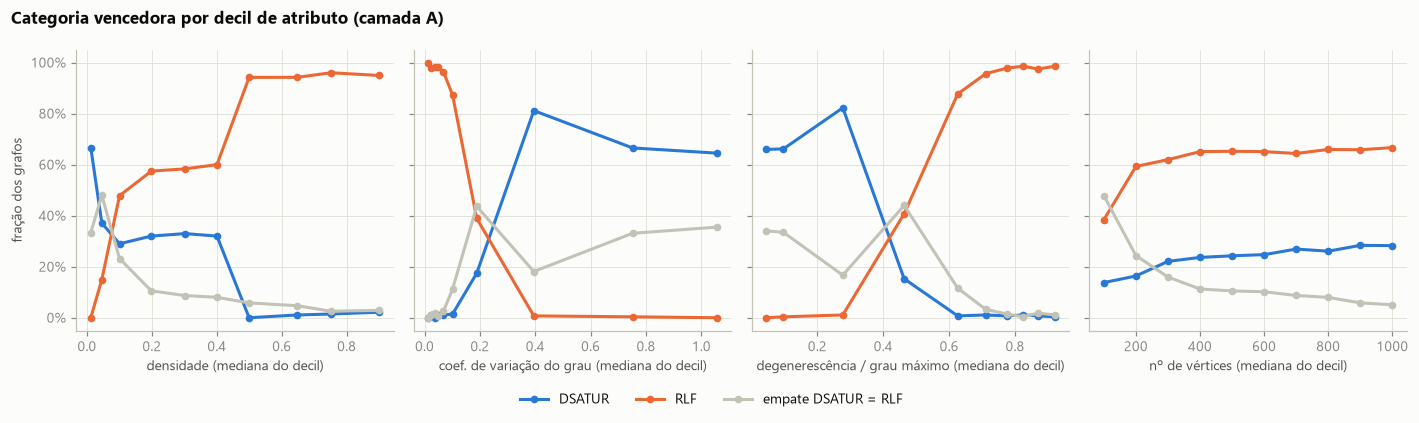

*Figura 4 — Fração de grafos em cada categoria vencedora, por decil de quatro atributos globais.*

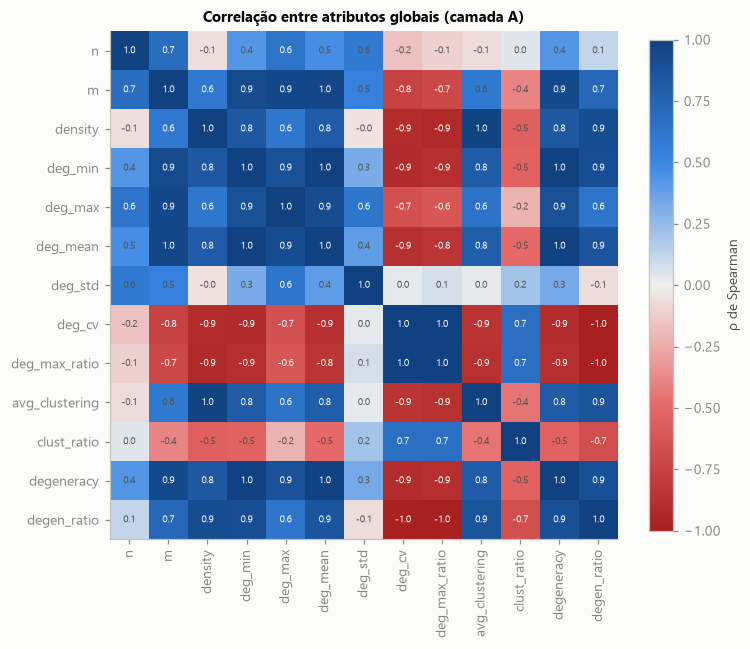

*Figura 5 — Correlação de Spearman entre os atributos globais.*

Blocos de atributos quase redundantes (ligados por |ρ| ≥ 0,95): {`m`, `deg_min`, `deg_mean`, `degeneracy`}; {`density`, `avg_clustering`}; {`deg_cv`, `deg_max_ratio`, `degen_ratio`}. Dentro de cada bloco, um atributo basta. Parte da redundância vem da própria grade: no ER, agrupamento ≈ densidade por construção; e `deg_cv`, `deg_max_ratio` e `degen_ratio` separam principalmente ER de BA.


In [6]:
eda.sec3_features(rep, A)

### Explore: as categorias vencedoras no plano de dois atributos
Pontos coloridos pela categoria vencedora. Tente `("density", "n")` só no ER
(`SO_FAMILIA = "er"`) para ver onde ficam os empates.

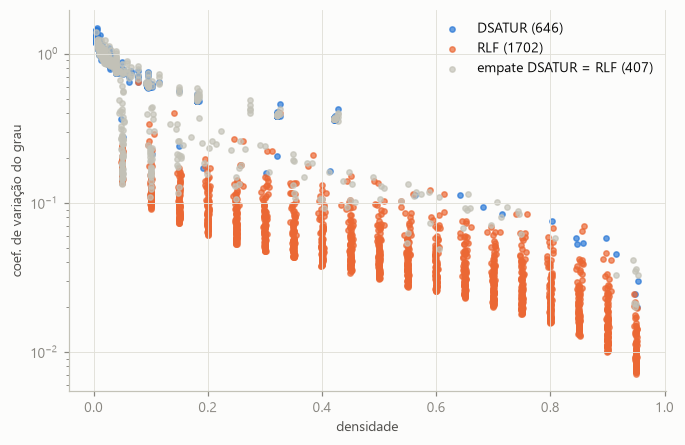

In [7]:
EIXO_X, EIXO_Y, SO_FAMILIA = "density", "deg_cv", None     # SO_FAMILIA: None, "er" ou "ba"

d = A if SO_FAMILIA is None else A[A.model == SO_FAMILIA]
fig, ax = plt.subplots(figsize=(7, 4.5))
for c in WCATS:
    dd = d[d.winner == c]
    if len(dd):
        ax.scatter(dd[EIXO_X], dd[EIXO_Y], s=12, alpha=0.7, color=WCOLOR[c], label=f"{c} ({len(dd)})")
ax.set_xlabel(FEATURE_DESC[EIXO_X]); ax.set_ylabel(FEATURE_DESC[EIXO_Y])
ax.set_yscale("log"); ax.legend(); plt.show()

## 4. Escala (camada S)

**Pergunta.** O que vale para n ≤ 1.000 continua valendo para n = 2.000 a 10.000?

**Como ler.** Compare as linhas de n = 500 e 1.000 (camada A) com as de n maior (camada S)
para o mesmo parâmetro: a coluna "(D−R)/melhor" mantém o sinal e a ordem de grandeza.

In [8]:
eda.sec4_scale(rep, A, S)

## 4. Escala (camada S)


Médias por configuração; as linhas com n = 500 e 1.000 vêm da camada A (5 réplicas), as demais da camada S (3 réplicas).


| modelo | parâmetro | n | grafos | cores Aleatória | cores Welsh-Powell | cores DSATUR | cores RLF | RLF < DSATUR | DSATUR < RLF | (D−R)/melhor |
|---|---|---|---|---|---|---|---|---|---|---|
| Barabási–Albert | 2,00 | 500 | 5 | 6,4 | 4,0 | 3,2 | 4,0 | 0% | 80% | -26,7% |
| Barabási–Albert | 2,00 | 1000 | 5 | 6,4 | 4,0 | 3,2 | 4,0 | 0% | 80% | -26,7% |
| Barabási–Albert | 2,00 | 2000 | 3 | 7,0 | 4,0 | 3,0 | 4,0 | 0% | 100% | -33,3% |
| Barabási–Albert | 2,00 | 5000 | 3 | 7,0 | 4,7 | 3,0 | 4,0 | 0% | 100% | -33,3% |
| Barabási–Albert | 2,00 | 10.000 | 3 | 8,0 | 4,0 | 3,0 | 4,0 | 0% | 100% | -33,3% |
| Barabási–Albert | 5,00 | 500 | 5 | 10,2 | 6,6 | 5,6 | 6,0 | 0% | 40% | -8,0% |
| Barabási–Albert | 5,00 | 1000 | 5 | 10,4 | 6,8 | 5,6 | 6,2 | 0% | 60% | -11,3% |
| Barabási–Albert | 5,00 | 2000 | 3 | 10,0 | 7,0 | 5,7 | 6,0 | 0% | 33% | -6,7% |
| Barabási–Albert | 5,00 | 5000 | 3 | 11,7 | 7,0 | 6,0 | 6,0 | 0% | 0% | 0,0% |
| Barabási–Albert | 5,00 | 10.000 | 3 | 13,3 | 7,0 | 5,3 | 6,0 | 0% | 67% | -13,3% |
| Barabási–Albert | 10,00 | 500 | 5 | 14,4 | 9,8 | 8,0 | 9,0 | 0% | 100% | -12,5% |
| Barabási–Albert | 10,00 | 2000 | 3 | 16,0 | 10,0 | 8,0 | 9,0 | 0% | 100% | -12,5% |
| Barabási–Albert | 10,00 | 5000 | 3 | 18,0 | 10,0 | 8,0 | 9,3 | 0% | 100% | -16,7% |
| Barabási–Albert | 10,00 | 10.000 | 3 | 18,3 | 10,3 | 8,3 | 9,3 | 0% | 67% | -12,5% |
| Barabási–Albert | 20,00 | 1000 | 5 | 23,2 | 15,2 | 12,6 | 14,0 | 0% | 100% | -11,3% |
| Barabási–Albert | 20,00 | 2000 | 3 | 23,7 | 15,3 | 12,3 | 14,0 | 0% | 100% | -13,7% |
| Barabási–Albert | 20,00 | 5000 | 3 | 26,0 | 15,7 | 12,0 | 14,0 | 0% | 100% | -16,7% |
| Barabási–Albert | 20,00 | 10.000 | 3 | 26,7 | 15,3 | 12,3 | 14,0 | 0% | 100% | -13,7% |
| Erdős–Rényi | 0,05 | 500 | 5 | 12,8 | 11,2 | 9,8 | 9,0 | 80% | 0% | 8,9% |
| Erdős–Rényi | 0,05 | 1000 | 5 | 19,4 | 17,6 | 15,4 | 14,4 | 60% | 0% | 7,1% |
| Erdős–Rényi | 0,05 | 2000 | 3 | 31,0 | 29,0 | 26,0 | 24,0 | 100% | 0% | 8,3% |
| Erdős–Rényi | 0,05 | 5000 | 3 | 61,3 | 58,3 | 52,7 | 49,0 | 100% | 0% | 7,5% |
| Erdős–Rényi | 0,05 | 10.000 | 3 | 103,7 | 100,3 | 92,7 | 86,0 | 100% | 0% | 7,8% |
| Erdős–Rényi | 0,10 | 500 | 5 | 19,4 | 18,2 | 15,8 | 15,0 | 80% | 0% | 5,3% |
| Erdős–Rényi | 0,10 | 1000 | 5 | 31,8 | 29,4 | 26,4 | 24,4 | 100% | 0% | 8,2% |
| Erdős–Rényi | 0,10 | 2000 | 3 | 52,7 | 50,3 | 45,3 | 42,0 | 100% | 0% | 7,9% |
| Erdős–Rényi | 0,10 | 5000 | 3 | 106,7 | 102,7 | 94,7 | 88,0 | 100% | 0% | 7,6% |
| Erdős–Rényi | 0,10 | 10.000 | 3 | 185,0 | 179,7 | 169,7 | 159,0 | 100% | 0% | 6,7% |
| Erdős–Rényi | 0,20 | 500 | 5 | 32,0 | 30,2 | 27,6 | 25,2 | 100% | 0% | 9,6% |
| Erdős–Rényi | 0,20 | 1000 | 5 | 53,2 | 51,2 | 46,8 | 43,2 | 100% | 0% | 8,3% |
| Erdős–Rényi | 0,20 | 2000 | 3 | 92,0 | 88,7 | 82,3 | 75,7 | 100% | 0% | 8,8% |
| Erdős–Rényi | 0,20 | 5000 | 3 | 191,3 | 187,0 | 176,3 | 165,0 | 100% | 0% | 6,9% |
| Erdős–Rényi | 0,20 | 10.000 | 3 | 342,0 | 335,0 | 320,3 | 301,7 | 100% | 0% | 6,2% |


Na camada S, o RLF é estritamente melhor que o DSATUR em 100% dos grafos ER e em 0% dos BA. O tempo mediano do RLF em n = 10.000 foi de 1,4 s, contra 0,9 s do DSATUR. O padrão da camada A se mantém em escala (mesma heurística à frente em cada modelo).


### Explore: cores × n em escala log, juntando A e S

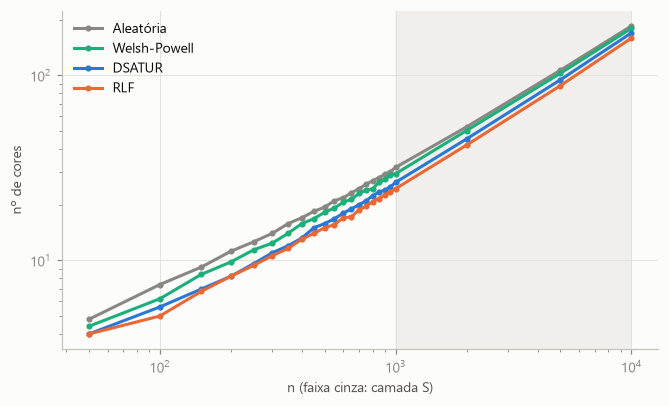

In [9]:
FAMILIA, PARAM = "er", 0.1        # parâmetros presentes na camada S: ER p ∈ {0.05, 0.1, 0.2}; BA m ∈ {2, 5, 10, 20}

d = pd.concat([A, S])
d = d[(d.model == FAMILIA) & np.isclose(d.param, PARAM)]
fig, ax = plt.subplots(figsize=(7, 4))
for h in H:
    s = d.groupby("n")[f"colors_{h}"].mean()
    ax.plot(s.index, s, color=HCOLOR[h], label=HNAME[h], marker="o", markersize=3)
ax.axvspan(1000, d.n.max(), color="#f0efec", zorder=0)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("n (faixa cinza: camada S)"); ax.set_ylabel("nº de cores")
ax.legend(); plt.show()

## 5. Trajetórias por passo (camada A)

**Pergunta.** Como cada heurística constrói a coloração ao longo dos passos? Isso importa
porque o modelo decide **passo a passo**, e os estados que ele vê dependem de quem tomou as
decisões anteriores.

**Como ler.** Na Figura 6, o eixo x é a fração de vértices já coloridos e o eixo y, as cores
abertas até ali (relativas ao total da melhor heurística). O DSATUR e o Welsh-Powell sobem
rápido e estabilizam (abrem as cores cedo e depois reutilizam); o RLF sobe em linha reta
(fecha uma cor de cada vez). Por isso "quem usou menos cores até o passo t" não diz quem
vai terminar melhor.

## 5. Trajetórias por passo (camada A)


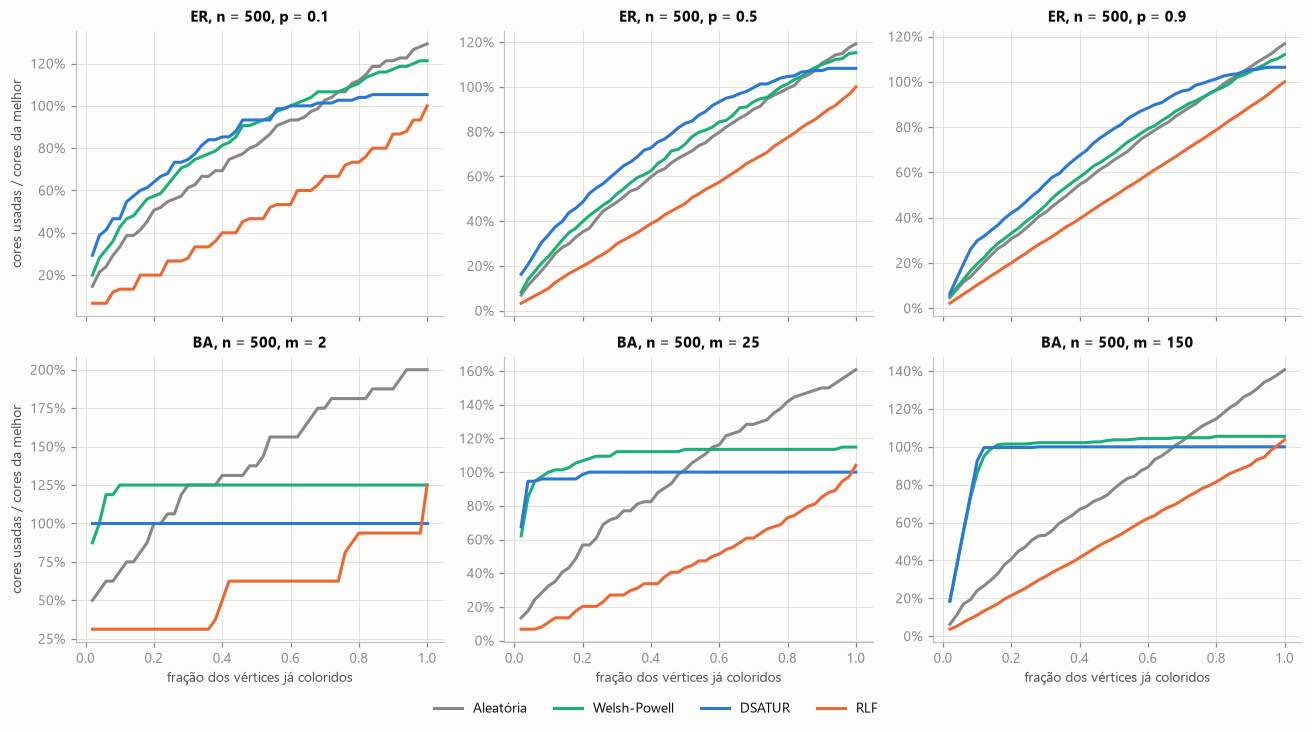

*Figura 6 — Cores acumuladas ao longo da construção, relativas ao total da melhor heurística (média das 5 réplicas).*

Fração das cores finais de cada heurística já abertas quando 10%, 25% e 50% dos vértices estão coloridos (média na camada A):


| heurística | BA 10% | BA 25% | BA 50% | ER 10% | ER 25% | ER 50% |
|---|---|---|---|---|---|---|
| Aleatória | 26% | 42% | 65% | 19% | 35% | 60% |
| Welsh-Powell | 88% | 96% | 99% | 24% | 42% | 67% |
| DSATUR | 97% | 99% | 100% | 35% | 55% | 80% |
| RLF | 15% | 23% | 45% | 11% | 24% | 48% |


As heurísticas constroem a coloração de formas estruturalmente diferentes. O DSATUR e o Welsh-Powell abrem a maior parte das cores cedo (no ER, o DSATUR já abriu 80% das suas cores na metade da construção) e depois reutilizam; o RLF fecha uma classe de cor por vez, então abre cores em ritmo quase constante (48% na metade). Consequências: (i) comparar "cores usadas até o passo t" entre heurísticas não indica quem está à frente — a diferença final só se revela no fim; (ii) os atributos por passo (`n_colors_before`, `step_frac`, `avail_color`) têm distribuições diferentes conforme a política que gerou o estado. Um modelo treinado em estados de uma política verá estados diferentes ao seguir a própria política (mudança de distribuição), o que precisa ser considerado na prova de conceito.


In [10]:
eda.sec5_trajectories(rep, DATA, A)

### Explore: a trajetória de um grafo específico
Escolha um `graph_id` da camada A (ex.: `er_n300_p0.50_s0`, `ba_n500_m25_s1`). O painel da
esquerda mostra as cores abertas; o da direita, a saturação do vértice escolhido em cada passo
(o DSATUR escolhe sempre a maior).

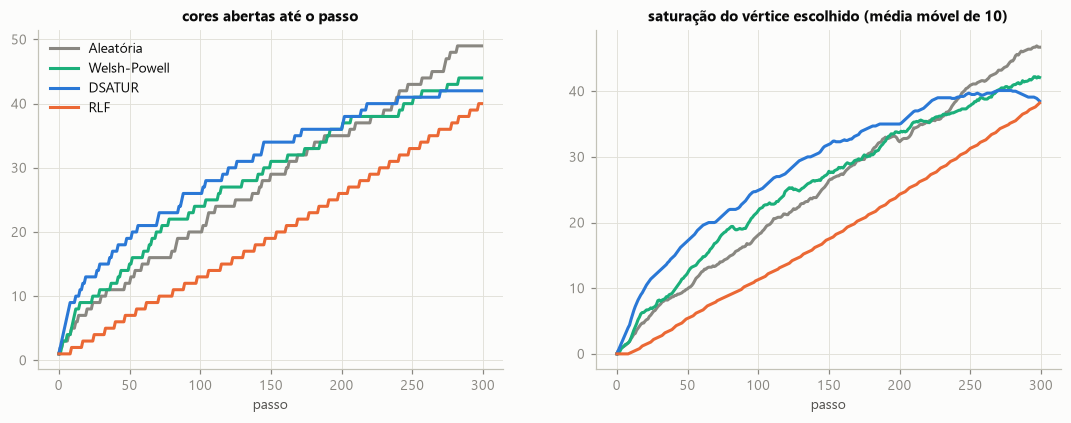

,colors_random,colors_welsh_powell,colors_dsatur,colors_rlf,winner
2007,49.0,44.0,42.0,40.0,RLF


In [11]:
GRAPH_ID = "er_n300_p0.50_s0"

st = pd.read_parquet(DATA / "A" / "steps", filters=[("graph_id", "==", GRAPH_ID)])
if st.empty:
    print("graph_id não encontrado; exemplos:", A.graph_id.sample(5, random_state=0).tolist())
else:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for h in H:
        s = st[st.heuristic == h].sort_values("step")
        axes[0].plot(s.step, s.n_colors_before + s.opens_new_color, color=HCOLOR[h], label=HNAME[h])
        axes[1].plot(s.step, s.saturation.rolling(10, min_periods=1).mean(), color=HCOLOR[h], label=HNAME[h])
    axes[0].set_title("cores abertas até o passo"); axes[1].set_title("saturação do vértice escolhido (média móvel de 10)")
    for ax in axes: ax.set_xlabel("passo")
    axes[0].legend(); plt.show()
    display(A.loc[A.graph_id == GRAPH_ID, [f"colors_{h}" for h in H] + ["winner"]])

## 6. Rótulos por passo (camada B)

**Pergunta.** Os rótulos por passo (opção 3b) têm sinal suficiente para treinar um modelo?
Quantos passos realmente exigem uma decisão? Que linha de base o modelo precisa superar?

**Como ler.** Na Figura 8, à esquerda: no ER, a maioria dos passos é informativa; no BA,
quase nenhum (todas as sugestões dão o mesmo resultado). À direita: em cada fase da
construção, com que frequência o candidato de cada heurística é ótimo — o do RLF acerta
~90% até perto do fim, quando o do DSATUR passa a acertar mais. A tabela de regras mostra
que escolher o candidato de menor `avail_color` (a menor cor disponível) já acerta ~82%.

## 6. Rótulos por passo (camada B)


As linhas da camada B seguem a **trajetória do oráculo**: os estados vistos são os que o oráculo visita, não os de cada heurística isolada.


Passos: 227.100. Candidatos distintos por passo: 1 = 0,5%, 2 = 2,1%, 3 = 16,2%, 4 = 81,2%. **Passos informativos** (ao menos um candidato com rótulo 0): **58,6%**. Nos demais, todas as sugestões levam ao mesmo valor e o passo não ensina nada ao modelo.


Balanço das classes: rótulo 1 em 65,6% de todas as linhas e em 42,7% das linhas dos passos informativos. Nos passos informativos, a diferença entre o melhor e o pior candidato é de 1,64 cores em média (mediana 1).


Por modelo: 82,2% dos passos são informativos no ER e 6,1% no BA — os passos informativos são 97% ER. No BA quase todas as sugestões levam ao mesmo número de cores (o DSATUR já é, em geral, ótimo ou quase), então o sinal de treino por passo vem essencialmente do ER.


Com que frequência o candidato escolhido pelo oráculo era a sugestão de cada heurística (sugestões coincidentes contam para todas): **todos** — Aleatória 2%, Welsh-Powell 7%, DSATUR 62%, RLF 41%; **informativos** — Aleatória 1%, Welsh-Powell 3%, DSATUR 35%, RLF 66%; **triviais** — Aleatória 4%, Welsh-Powell 12%, DSATUR 100%, RLF 6%. Nos passos triviais o desempate (DSATUR > RLF > WP > aleatória) faz o oráculo seguir o DSATUR; nos informativos ele segue sobretudo o RLF. Os estados da camada B são, portanto, uma mistura dos dois estilos de construção.



Fração dos passos em que o candidato sugerido por cada heurística é ótimo (rótulo 1). Referência: escolher um candidato distinto ao acaso acerta 42,8% dos passos informativos.


| candidato de | acerta (todos os passos) | acerta (informativos) | acerta (inform., ER) | acerta (inform., BA) | única a acertar (inform.) |
|---|---|---|---|---|---|
| Aleatória | 54,2% | 21,9% | 21,1% | 44,9% | 0,3% |
| Welsh-Powell | 56,9% | 26,4% | 25,1% | 66,0% | 0,1% |
| DSATUR | 61,9% | 35,1% | 33,0% | 97,4% | 5,2% |
| RLF | 93,1% | 88,3% | 89,1% | 63,7% | 41,7% |


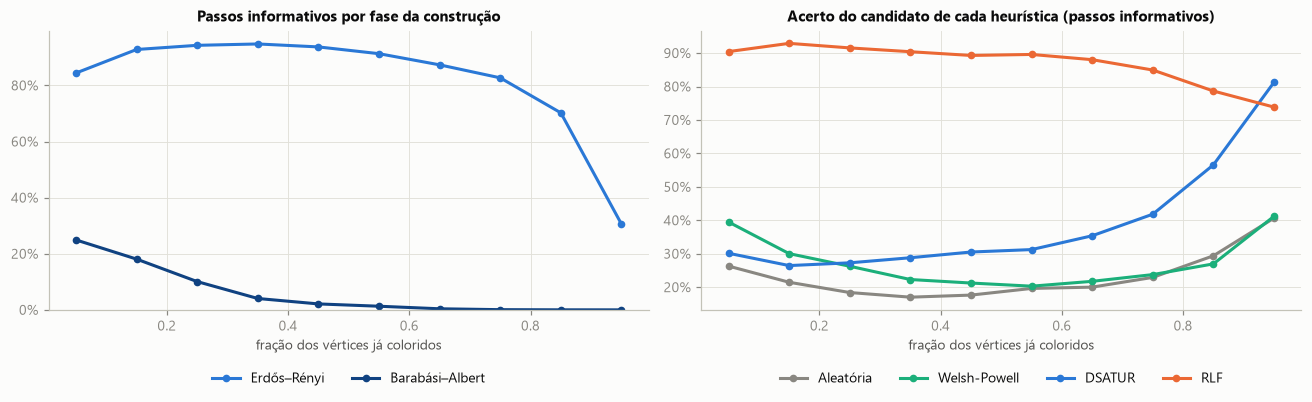

*Figura 8 — Fração de passos informativos e taxa de acerto das sugestões de cada heurística ao longo da construção.*


Regras de um único atributo nos passos informativos: escolher o candidato de maior (`max`) ou menor (`min`) valor; empates entre candidatos contam como sorteio (acerto esperado = fração de rótulos 1 entre os empatados).


| regra | acerto (geral) | acerto (ER) | acerto (BA) |
|---|---|---|---|
| seguir RLF | 88,3% | 89,1% | 63,7% |
| min(avail_color) | 81,9% | 82,7% | 58,0% |
| min(saturation) | 71,2% | 72,1% | 45,7% |
| min(opens_new_color) | 66,3% | 66,4% | 63,8% |
| min(colored_nb) | 57,5% | 57,8% | 48,6% |
| min(degree) | 46,6% | 46,4% | 50,5% |
| candidato ao acaso | 42,8% | 42,0% | 66,3% |
| max(uncolored_nb) | 40,8% | 39,9% | 66,3% |
| seguir DSATUR | 35,1% | 33,0% | 97,4% |
| min(uncolored_nb) | 35,1% | 34,4% | 53,7% |
| max(saturation) | 31,7% | 29,5% | 95,6% |
| max(avail_color) | 27,8% | 25,9% | 85,7% |
| max(colored_nb) | 27,0% | 25,3% | 79,2% |
| max(degree) | 26,6% | 25,3% | 66,2% |
| seguir Welsh-Powell | 26,4% | 25,1% | 66,0% |
| max(opens_new_color) | 25,3% | 23,7% | 71,9% |
| seguir Aleatória | 21,9% | 21,1% | 44,9% |



Dentro de cada passo informativo: média do atributo nos candidatos ótimos menos a média nos não ótimos.


| atributo | diferença média | rótulo 1 maior | iguais | rótulo 1 menor |
|---|---|---|---|---|
| degree | -2,54 | 36% | 2% | 63% |
| saturation | -0,50 | 21% | 7% | 72% |
| uncolored_nb | 0,69 | 54% | 4% | 43% |
| colored_nb | -3,23 | 28% | 3% | 69% |
| avail_color | -0,84 | 18% | 4% | 78% |
| opens_new_color | -0,41 | 6% | 28% | 67% |



Ganho do oráculo sobre a melhor das 4 heurísticas:


| modelo | grafos | melhora | ganho médio (cores) | ganho máx. (cores) | ganho médio (%) | tempo médio (s) |
|---|---|---|---|---|---|---|
| Barabási–Albert | 243 | 13% | 0,13 | 1 | 1,5% | 11,40 |
| Erdős–Rényi | 570 | 73% | 1,48 | 9 | 3,5% | 14,50 |


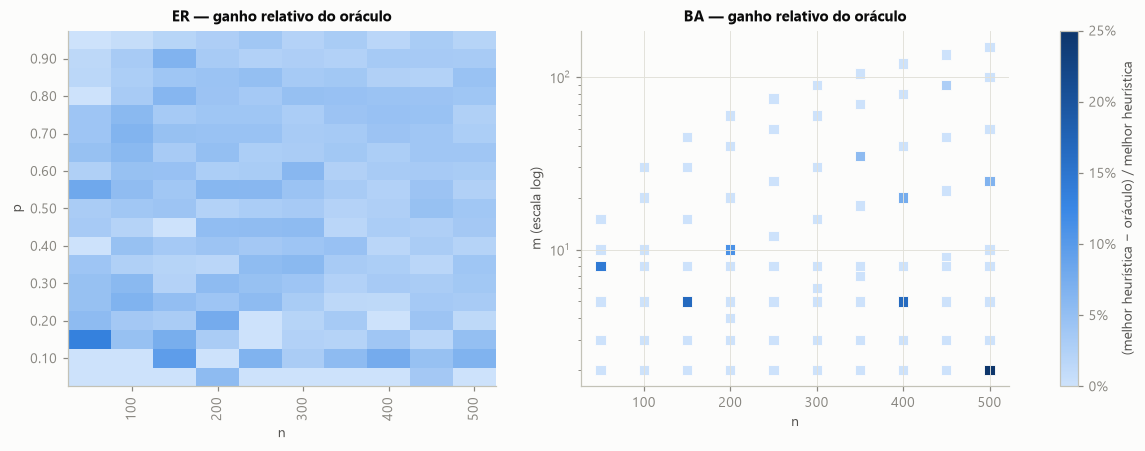

*Figura 9 — Ganho relativo do oráculo sobre a melhor heurística, por região da camada B (média das réplicas).*

In [12]:
b = eda.sec6_rollouts(rep, DATA, A)

### Explore: os candidatos passo a passo num grafo da camada B
Cada linha mostra o **valor** (nº de cores ao completar a coloração) do candidato sugerido por
cada heurística em cada passo; a linha preta tracejada é o valor escolhido pelo oráculo. As
faixas cinza marcam os passos informativos, em que alguma sugestão é pior que a melhor.

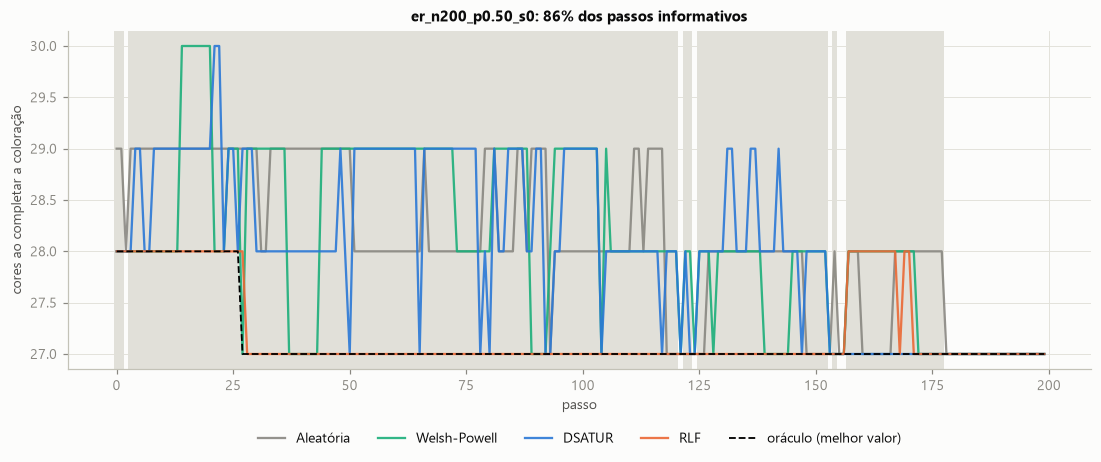

,graph_id,model,n,param,seed,oracle_colors,n_rollouts,rows,seconds,colors_random,colors_welsh_powell,colors_dsatur,colors_rlf
527,er_n200_p0.50_s0,er,200,0.5,0,27,1080,739,6.395937,36,33,32,28


In [13]:
GRAPH_ID_B = "er_n200_p0.50_s0"        # ex.: "er_n100_p0.20_s1", "ba_n300_m15_s0"

r = B[B.graph_id == GRAPH_ID_B]
if r.empty:
    print("não está na camada B; exemplos:", O.graph_id.sample(5, random_state=0).tolist())
else:
    fig, ax = plt.subplots(figsize=(12, 4))
    best = r.groupby("step").rollout_colors.min()
    inf = r.groupby("step").label.min() == 0
    for t in inf[inf].index:
        ax.axvspan(t - 0.5, t + 0.5, color="#e1e0d9", linewidth=0)
    for h in H:
        s = r[r.suggested_by.str.contains(h, regex=False)].set_index("step").rollout_colors
        ax.plot(s.index, s, color=HCOLOR[h], label=HNAME[h], linewidth=1.5, alpha=0.9)
    ax.plot(best.index, best, color="black", linestyle="--", linewidth=1.2, label="oráculo (melhor valor)")
    ax.set_xlabel("passo"); ax.set_ylabel("cores ao completar a coloração")
    ax.legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.15))
    ax.set_title(f"{GRAPH_ID_B}: {inf.mean():.0%} dos passos informativos")
    plt.show()
    display(O[O.graph_id == GRAPH_ID_B])

## 7. Conclusões para o modelo

As conclusões abaixo são geradas a partir dos números acima; são a base da prova de conceito
(`scripts/train_poc.py`, relatório em `results/poc_modelo/RELATORIO_MODELO.md`).

In [14]:
eda.sec7_conclusions(rep, A, b)

## 7. Conclusões para o modelo (sugestões, a discutir)


1. **A disputa é entre DSATUR e RLF, e a família do grafo quase a decide.** Welsh-Powell e ordem aleatória nunca são estritamente as melhores. No ER o RLF vence (ou empata) quase sempre; no BA, o DSATUR. Os atributos globais mais informativos (um por bloco redundante) são `deg_cv`, `clust_ratio`, `degeneracy`, mas eles separam sobretudo ER de BA: dentro de cada família, os mais informativos são `deg_max` (ER) e `deg_min` (BA). Um classificador por grafo (opção 1) tende a aprender a família geradora; ele deve ser avaliado também separadamente por modelo, e o teste no DIMACS dirá se generaliza.
2. **Atributos redundantes.** Blocos com |ρ| ≥ 0,95: {`m`, `deg_min`, `deg_mean`, `degeneracy`}; {`density`, `avg_clustering`}; {`deg_cv`, `deg_max_ratio`, `degen_ratio`}. Basta um atributo por bloco.
3. **Rótulo por passo (opção 3b): treinar só nos passos informativos.** Apenas 58,6% dos passos da camada B são informativos (82,2% no ER, 6,1% no BA). Treinar em todos inflaria a acurácia com exemplos triviais; sugere-se treinar e avaliar a classificação apenas nos passos informativos e reportar à parte a fração de triviais. O sinal de treino por passo vem quase todo do ER.
4. **Linha de base a superar.** Nos passos informativos, seguir o RLF acerta 88,3% (no BA, onde há poucos passos informativos, a melhor sugestão é a do DSATUR, com 97,4%); a melhor regra de um atributo (`min(avail_color)`) acerta 81,9%; ao acaso, 42,8%. A regra `min(avail_color)` é essencialmente o princípio do RLF (completar a classe de cor atual antes de abrir outra), o que explica seu bom desempenho. O modelo precisa superar o candidato do RLF — e, sobretudo, usar menos cores ao **seguir a própria política** de ponta a ponta, que é a métrica do objetivo geral.
5. **Mudança de distribuição.** Os estados da camada B vêm da trajetória do oráculo (uma mistura de passos no estilo DSATUR e no estilo RLF), e cada política produz estados com distribuições diferentes (seção 5). Ao seguir a própria política, o modelo verá estados que não estavam no treino. Para a prova de conceito isso é aceitável, mas deve ser medido (acerto por passo versus cores finais) e registrado como limitação a tratar no POC II (ex.: gerar rótulos também nos estados visitados pelo próprio modelo).
6. **Formulação sugerida para a prova de conceito:** classificação binária de candidatos (rótulo 3b) nos passos informativos, com atributos do candidato (tabela da seção 6), atributos relativos ao passo (ex.: `avail_color` comparado ao nº de cores já usadas; posição de cada atributo entre os candidatos do passo) e atributos globais do grafo (um por bloco); escolha do candidato de maior probabilidade; divisão treino/validação por grafo, estratificada por modelo e n; avaliação por acerto nos passos informativos e por nº de cores da coloração completa obtida com a política aprendida, comparado ao DSATUR, ao RLF e ao oráculo.
